## 01 — Diagnosing ambiguous XDec profiles (TCGA-PAAD, n=150, k=9)

* **Aim:**
In the initial run, Profile_7 correlated broadly with reference expression across nearly all cell types but was the dominant profile in only one sample. This pattern raises concern about a possible NNLS estimation artifact, although it is not conclusive. To investigate its cause, I am aligning the inputs and parameters with the paper—its 149-sample tumor cohort, k=9, Table S3 probes, and reference preprocessing—and testing whether the profile persists as each discrepancy is addressed.

**Possible reasons for the apparent artifact and failure to reproduce the paper**

**Paper settings:** 149 TCGA-PAAD samples, k=9, and 283 informative genes reported in Table S3. Run A matches k and uses the 282 recovered Table S3 symbols, of which 247 enter the local profile–reference correlation calculation. The cohort remains 150 samples. The paper describes bulk tumors and does not report adding normal-tissue controls to the 149-sample cohort; confirming sample types individually requires the original barcodes. Normal epithelial reference cells and nonmalignant cells within tumors are distinct from separate normal-tissue bulk samples. See the [paper, Results and STAR Methods](https://pmc.ncbi.nlm.nih.gov/articles/PMC9579012/).

These checks narrow the explanations for ambiguous profiles; they do not yet establish that those profiles are artifacts or reproduce the paper's two cancer states.

| Possible reason | Assessment | Evidence and limitation | Next check |
|---|---|---|---|
| Unfiltered bulk samples | Insufficient as the sole explanation; not fully ruled out | Ambiguity persists in the 150-sample subset. This is not the paper's exact 149-sample cohort; the earlier 182-sample comparison also changes k. | Compare cohorts at fixed k and verify the exact sample list. |
| Selected probes | Partial contribution; paper-derived list already tested in A | Run A uses the extracted Table S3 list (282 recovered symbols; 247 usable for correlation), not the original Stage 0 list. Maximum breadth falls from 10/10 to 5/10 in A and 4/10 after prefix filtering. Both fitting and evaluation genes change, so improved biological recovery is unproven. | Match profiles and evaluate on shared genes across repeated fits. |
| Different reference preprocessing | Tested approximation does not resolve the mismatch | Corrected five-cell pseudo-bulk Run D retains breadth 7/10. Original cell depths are unavailable; random grouping replaces depth-ranked grouping. Double-transformed Run C is excluded. | Reconstruct the original preprocessing if source data become available. |
| Missing exponential transform | Ruled out in the current CLI | Local normalization already applies the per-gene transform to bulk and reference inputs. This does not establish full normalization parity with the paper. | Verify the remaining normalization steps; do not preapply the transform. |
| Reference composition or expression source | Unresolved | Local reference and bulk inputs are not verified equivalents of the paper's inputs. Cell selection, annotations, units, and malignant-state coverage may differ. | Verify input provenance and reference coverage; inspect epithelial markers and independent tumor purity. |
| Different k from the paper | Ruled out for the current runs | Both the paper and the current runs use k=9. Matching k does not guarantee the same fitted profiles. | Keep k=9 for the direct reproduction comparison. |
| Initialization and convergence | Unresolved; testable | A single seed does not establish a stable fit. The joint alternating factorization is nonconvex, although individual NNLS subproblems are convex. | Repeat seeds at k=9; assess matched-profile stability and reconstruction residuals. |
| Implementation differences | Unresolved | The Python port has not been validated end to end against the paper's implementation on identical inputs. | Compare normalization, probe selection, optimization settings, and outputs on matched inputs. |

**Priority:** compare cohorts at fixed k, evaluate matched profiles on shared genes across seeds, and test epithelial markers and independent tumor purity before assigning unmatched profiles to cancer states.


In [3]:
from pathlib import Path
import os
import re
import subprocess

import numpy as np
import pandas as pd

# Find progress/ from either the notebook directory or progress/ itself.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "tools/XDec_SM/python/xdec.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start from progress/ or one of its subdirectories.")
os.chdir(ROOT)
XDEC_DIR = "data/deconvolution/xdec"
RBASE_RSCRIPT = str(Path.home() / ".pixi/envs/r-base/bin/Rscript")
PYTHON_PIXI = str(Path.home() / ".pixi/envs/python/bin/python3")
XDEC_SCRIPT = "tools/XDec_SM/python/xdec.py"
RUN_PIPELINE = False  # Opt in to generating missing outputs; existing outputs are reused.
CORR_THRESHOLD = 0.3


def run_checked(command):
    if not RUN_PIPELINE:
        raise FileNotFoundError("Missing pipeline output. Set RUN_PIPELINE=True to generate it.")
    result = subprocess.run(command, capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError(f"Command failed ({result.returncode}): {command}\n"
                           f"{result.stdout}\n{result.stderr}")
    print(result.stdout)
    return result


def read_genes(path):
    genes = Path(path).read_text().splitlines()
    return list(dict.fromkeys(g.strip() for g in genes if g.strip()))


def validate_outputs(props, corr, means):
    for name, frame in {"proportions": props, "correlation": corr, "means": means}.items():
        if not frame.index.is_unique or not frame.columns.is_unique:
            raise ValueError(f"Duplicate labels in {name}")
        if not np.isfinite(frame.to_numpy()).all():
            raise ValueError(f"Nonfinite values in {name}")
    if set(props.columns) != set(corr.columns) or set(props.columns) != set(means.columns):
        raise ValueError("Profile labels disagree between Stage 1/2 outputs")
    if props.shape != (150, 9) or not props.index.equals(restricted_columns):
        raise ValueError("Proportions do not match the ordered 150-sample cohort at k=9")
    if (props.to_numpy() < 0).any() or (means.to_numpy() < 0).any():
        raise ValueError("Negative proportions or Stage 2 means")
    if not np.allclose(props.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Proportions do not sum to one")
    if (np.abs(corr.to_numpy()) > 1 + 1e-8).any():
        raise ValueError("Correlation outside [-1, 1]")

### 1. Unfiltered samples

The [pipeline README](../scripts/README.md) describes the original download and QC workflow. The detailed [sample-filtering rationale](sample_filtering.md) explains why the full 182-sample input differs from the 150-sample PanCanAtlas cohort used here and XDec-CHI's reported 149 samples.

Use the local `TCGAbiolinks::TCGAquery_subtype(tumor="paad")` export to restrict the cohort. Match at the 16-character sample/vial level and reject duplicate matches or missing samples. Validate an existing subset against the source counts before reuse.


In [4]:
subtype_dir = os.path.join(XDEC_DIR, "subtypes")
subtype_tsv = os.path.join(subtype_dir, "paad_panCanAtlas_subtypes.tsv")
r_script_path = os.path.join(subtype_dir, "pull_paad_subtypes.R")

if not os.path.exists(subtype_tsv):
    os.makedirs(subtype_dir, exist_ok=True)
    result = run_checked([RBASE_RSCRIPT, r_script_path])
assert os.path.exists(subtype_tsv)

subtypes = pd.read_csv(subtype_tsv, sep="\t")
print(subtypes.shape)
subtypes.head(3)

(150, 6)


,tumor_sample_id,moffitt_cluster,bailey_cluster,collisson_cluster,absolute_purity,purity_class
0,TCGA-2J-AAB1-01A,Classical,Progenitor,Classical,0.38,high
1,TCGA-2J-AAB4-01A,Classical,Progenitor,Classical,0.30,low
2,TCGA-2J-AAB6-01A,Basal,Squamous,QM,0.54,high


In [5]:
restricted_bulk_path = os.path.join(XDEC_DIR, "TCGA-PAAD_counts_raw_n150.tsv")
counts = pd.read_csv("data/processed/TCGA-PAAD_counts_raw.tsv", sep="\t", index_col=0)
cohort = subtypes["tumor_sample_id"].astype(str).str.strip()
if len(cohort) != 150 or not cohort.is_unique or not cohort.str.len().eq(16).all():
    raise ValueError("Expected 150 unique 16-character subtype barcodes")
if not counts.columns.is_unique or not counts.index.is_unique:
    raise ValueError("Duplicate bulk sample or gene labels")
barcodes = counts.columns.str[:16]
keep = barcodes.isin(cohort)
matched = barcodes[keep]
if not matched.is_unique or set(matched) != set(cohort):
    raise ValueError("Bulk-to-cohort matching is missing samples or is not one-to-one")
restricted = counts.loc[:, keep]
restricted_columns = restricted.columns
if Path(restricted_bulk_path).exists():
    cached = pd.read_csv(restricted_bulk_path, sep="\t", index_col=0)
    pd.testing.assert_frame_equal(cached, restricted, check_dtype=False)
else:
    if not RUN_PIPELINE:
        raise FileNotFoundError("Missing cohort subset; set RUN_PIPELINE=True to create it")
    restricted.to_csv(restricted_bulk_path, sep="\t")
print(f"Validated {restricted.shape[0]} genes × {restricted.shape[1]} samples")
del counts, restricted

Validated 59427 genes × 150 samples


Use the original reference and Stage 0 probes, k=9, and the CLI's default seed (12345). Existing outputs are reused, not regenerated. Completeness and matrix consistency are checked below; these checks cannot establish the provenance of legacy cached fits. Changing inputs requires new output directories or deliberate cache invalidation.

In [6]:
stage1_dir = os.path.join(XDEC_DIR, "stage1_with_refs_k9_n150")
os.makedirs(stage1_dir, exist_ok=True)
proportions_path = os.path.join(stage1_dir, "proportions.tsv")

if not all(Path(stage1_dir, name).exists() for name in
           ("proportions.tsv", "cell_type_profiles.tsv", "correlation.tsv")):
    result = run_checked(
        [PYTHON_PIXI, XDEC_SCRIPT, "stage1",
         "--bulk", restricted_bulk_path,
         "--probes", os.path.join(XDEC_DIR, "stage0", "selected_probes.txt"),
         "--refs", os.path.join(XDEC_DIR, "refs.tsv"),
         "--ref-metadata", os.path.join(XDEC_DIR, "ref_metadata.tsv"),
         "--k", "9",
         "--outdir", stage1_dir],
    )

proportions = pd.read_csv(proportions_path, sep="\t", index_col=0)
proportions.shape

(150, 9)

In [7]:
stage2_dir = os.path.join(XDEC_DIR, "stage2_with_refs_k9_n150")
os.makedirs(stage2_dir, exist_ok=True)
means_path = os.path.join(stage2_dir, "stage2_means.tsv")

if not all(Path(stage2_dir, name).exists() for name in
           ("stage2_means.tsv", "stage2_stderrs.tsv")):
    result = run_checked(
        [PYTHON_PIXI, XDEC_SCRIPT, "stage2",
         "--bulk-counts", restricted_bulk_path,
         "--proportions", proportions_path,
         "--outdir", stage2_dir],
    )

stage2_means = pd.read_csv(means_path, sep="\t", index_col=0)
stage2_means.shape

(53885, 9)

Report three complementary summaries, without treating them as independent proof of an artifact:

- **Dominance:** number of samples where a profile has the largest fitted proportion; this is not prevalence or a count above 50%.
- **Breadth:** reference types with mean single-cell Spearman correlation >0.3, as calculated by the local CLI over the run's usable probes. Zero breadth means no correlation exceeds this threshold, not zero correlation.
- **Boundary estimates:** genes above the candidate's 99th expression percentile with an exact zero in another profile. The partner maximizes this count; it is not necessarily the most biologically similar profile. These are descriptive contrasts, not differential-expression tests.

Profile_7 is inspected only in the baseline fit. Cross-run comparisons below select the broadest profile separately and do not assume matching profile identities.

In [8]:
corr = pd.read_csv(os.path.join(stage1_dir, "correlation.tsv"), sep="\t", index_col=0)
validate_outputs(proportions, corr, stage2_means)
corr.shape

(10, 9)

In [9]:
dominant_counts = proportions.idxmax(axis=1).value_counts().reindex(proportions.columns, fill_value=0)
dominant_counts

Profile_1    88
Profile_2    10
Profile_3     2
Profile_4    21
Profile_5     1
Profile_6     0
Profile_7     4
Profile_8    23
Profile_9     1
Name: count, dtype: int64

In [10]:
broad_corr = (corr > CORR_THRESHOLD).sum(axis=0).sort_values(ascending=False)
broad_corr.rename("n_reference_types_with_r_gt_0.3")

Profile_7    10
Profile_3     1
Profile_1     0
Profile_2     0
Profile_4     0
Profile_5     0
Profile_6     0
Profile_8     0
Profile_9     0
Name: n_reference_types_with_r_gt_0.3, dtype: int64

In [11]:
profile7_means = stage2_means["Profile_7"]

zero_floor_rows = []
for other in stage2_means.columns:
    if other == "Profile_7":
        continue
    other_vals = stage2_means[other]
    mask = (other_vals == 0) & (profile7_means > profile7_means.quantile(0.99))
    zero_floor_rows.append({"partner_profile": other, "n_genes_zero_floor": int(mask.sum())})
zero_floor_df = pd.DataFrame(zero_floor_rows).sort_values("n_genes_zero_floor", ascending=False)
zero_floor_df


,partner_profile,n_genes_zero_floor
1,Profile_2,118
4,Profile_5,117
7,Profile_9,111
3,Profile_4,94
5,Profile_6,42
6,Profile_8,34
2,Profile_3,33
0,Profile_1,22


In [12]:
best_partner = zero_floor_df.iloc[0]["partner_profile"]
mask = (stage2_means[best_partner] == 0) & (profile7_means > profile7_means.quantile(0.99))
top_genes = profile7_means[mask].sort_values(ascending=False).head(20)
print(f"top genes where Profile_7 is in its top 1% of expression and {best_partner} == 0.0:")
print(top_genes)

ribo_pattern = re.compile(r"^(RPL|RPS|MRPL|MRPS|EEF|RPLP)")
frac_ribo = top_genes.index.str.match(ribo_pattern).mean() if len(top_genes) else np.nan
print(f"\nfraction of these top 20 genes matching a ribosomal/translation gene-symbol pattern: {frac_ribo:.2f}")

top genes where Profile_7 is in its top 1% of expression and Profile_2 == 0.0:
RPL8        409544.579048
SERPINA1    230956.844874
S100A6      216131.980075
GAPDH       207166.486678
KRT17       181023.607115
KRT19       176128.957600
REG3A       119007.524162
REG1B       109254.263101
OLFM4        99909.312939
PKM          97241.452932
MUC2         90728.852485
SPINK1       88568.697540
REG4         82173.329367
TPI1         76881.241402
KRT18        76622.523498
TAGLN2       75776.304319
AGR2         68248.193859
HSPB1        64768.310986
ENO1         64124.923244
S100A11      61169.393135
Name: Profile_7, dtype: float64

fraction of these top 20 genes matching a ribosomal/translation gene-symbol pattern: 0.05


**Interpretation:** broad reference similarity and boundary estimates warrant further checks, but neither establishes a spurious component. The top boundary genes include epithelial/secretory as well as housekeeping-related symbols, so genuine epithelial signal remains plausible. Low dominance alone is compatible with a real minority compartment.

The earlier n=182/k=8 result and this n=150/k=9 result change both cohort and k. They cannot isolate a cohort effect; that requires comparing cohorts at the same k and assessing multiple initializations.

### 2. Selected probes (a confirmed partial cause)

Plot `log1p` of the exported reference values without per-gene standardization. This shows absolute expression patterns on the export's scale, not raw sequencing counts. The reference-only plot is unaffected by cohort restriction. Broad expression does not by itself imply lack of cell-type information; relative differences may remain informative.

The probe interventions below confirm that selected probes contribute to the observed correlation breadth. This is a partial explanation of the diagnostic signature; it does not establish that an entire profile is artifactual.


In [13]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})

FIG_DIR = os.path.join(XDEC_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# Single-hue sequential blue ramp (magnitude encoding), light -> dark.
SEQ_BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
                  "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_blue = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE_STEPS, N=256)


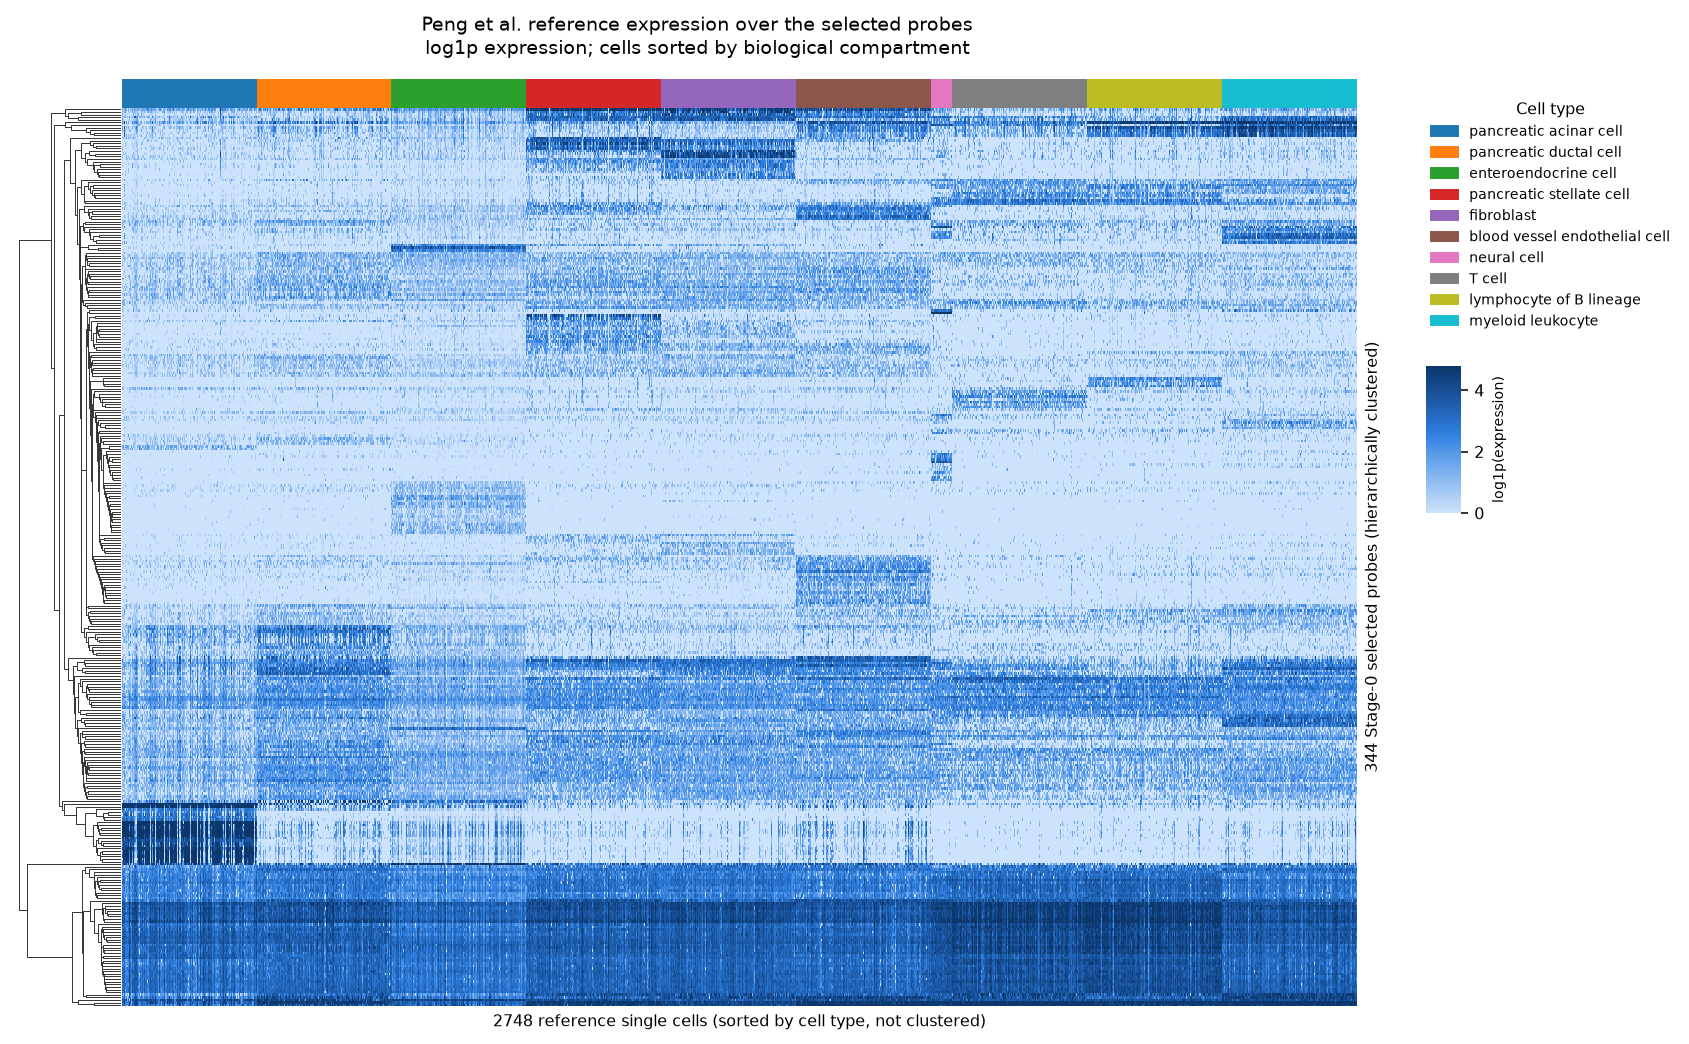

In [1]:
refs = pd.read_csv(os.path.join(XDEC_DIR, "refs.tsv"), sep="\t", index_col=0)
ref_meta = pd.read_csv(os.path.join(XDEC_DIR, "ref_metadata.tsv"), sep="\t", index_col=0)
probe_list = read_genes(os.path.join(XDEC_DIR, "stage0", "selected_probes.txt"))
valid_probes = [g for g in probe_list if g in refs.index]
print(f"{len(valid_probes)}/{len(probe_list)} probes present in refs.tsv")

if not refs.index.is_unique or not refs.columns.is_unique or not ref_meta.index.is_unique:
    raise ValueError("Duplicate reference or metadata labels")
if not np.isfinite(refs.to_numpy()).all() or (refs.to_numpy() < 0).any():
    raise ValueError("Reference must contain finite nonnegative expression")
ref_cell_types = ref_meta.loc[refs.columns, "Cell_Type"]
if ref_cell_types.isna().any() or len(valid_probes) < 2:
    raise ValueError("Missing cell types or insufficient shared probes")
# Match the biological order and annotation colors in 02_visualization.ipynb.
cell_type_order = [
    "pancreatic acinar cell", "pancreatic ductal cell", "enteroendocrine cell",
    "pancreatic stellate cell", "fibroblast", "blood vessel endothelial cell", "neural cell",
    "T cell", "lymphocyte of B lineage", "myeloid leukocyte",
]
if set(cell_type_order) != set(ref_cell_types.unique()):
    raise ValueError("Cell-type order must cover the reference metadata")
cell_palette = dict(zip(cell_type_order, sns.color_palette("tab10", len(cell_type_order))))
cell_order = ref_cell_types.map({t: i for i, t in enumerate(cell_type_order)}).sort_values(kind="stable").index
expr = np.log1p(refs.loc[valid_probes, cell_order])  # genes × cells; retain expression scale
col_colors = ref_cell_types.loc[cell_order].map(cell_palette)

g = sns.clustermap(
    expr, row_cluster=True, col_cluster=False,
    col_colors=col_colors.to_numpy(),
    cmap=seq_blue, vmin=0, vmax=float(np.percentile(expr.values, 99)),
    xticklabels=False, yticklabels=False,
    figsize=(10, 7), cbar_kws={"label": "log1p(expression)"},
    dendrogram_ratio=(0.08, 0.02),
)
g.ax_heatmap.set_xlabel(f"{len(cell_order)} reference single cells (sorted by cell type, not clustered)")
g.ax_heatmap.set_ylabel(f"{len(valid_probes)} Stage-0 selected probes (hierarchically clustered)")
handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend = g.ax_heatmap.legend(
    handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
    loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
)
g.fig.suptitle("Peng et al. reference expression over the selected probes\n"
               "log1p expression; cells sorted by biological compartment", y=1.03, fontsize=10)

# Align the expression colorbar beneath the cell-type legend, as in Figure 1 of notebook 02.
g.cax.yaxis.label.set_fontsize(7)
g.fig.canvas.draw()
legend_bbox = legend.get_window_extent(g.fig.canvas.get_renderer()).transformed(g.fig.transFigure.inverted())
g.cax.set_position([legend_bbox.x0, legend_bbox.y0 - 0.18, 0.025, 0.15])

expression_fig_dir = Path("paper_duplication/figures")
expression_fig_dir.mkdir(parents=True, exist_ok=True)
fig1_path = expression_fig_dir / "fig_reference_expression_clustermap_n150_k9.png"
g.savefig(fig1_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(g.fig)
print("saved", fig1_path)


**Interpretation:** dark columns identify broadly abundant probes on this scale. The comparison below ranks them quantitatively; abundance and cell-type specificity are distinct properties.

Compare the local Stage 0 list with the 282 unique symbols in the extracted Table S3 file. The local extraction is incomplete relative to the reported 283 entries; do not infer the missing symbol from a date-like string without checking the original table.

The symbol-prefix pattern below is a reproducible heuristic for ribosomal/translation and other broadly expressed gene families. It is not a curated housekeeping annotation, and matching genes may still carry biological signal.

In [15]:
paper_genes_path = os.path.join(XDEC_DIR, "gene_lists", "xdec_chi_table_s3_genes.txt")
paper_genes = read_genes(paper_genes_path)
paper_set = set(paper_genes)
our_set = set(probe_list)

overlap = our_set & paper_set
print(f"Our {len(our_set)} Stage-0 probes vs. the paper's {len(paper_set)} Table S3 genes:")
print(f"  overlap: {len(overlap)} genes "
      f"({len(overlap) / len(our_set):.1%} of ours, {len(overlap) / len(paper_set):.1%} of theirs)")

Our 344 Stage-0 probes vs. the paper's 282 Table S3 genes:
  overlap: 91 genes (26.5% of ours, 32.3% of theirs)


In [16]:
ribo_hk_pattern = re.compile(r"^(RPL|RPS|MRPL|MRPS|EEF|RPLP|TMSB|B2M$|ACTB$|GAPDH$|TUBB|TUBA|HSP|FTL$|FTH1$)")
our_hk = sorted(g for g in our_set if ribo_hk_pattern.match(g))
paper_hk = sorted(g for g in paper_set if ribo_hk_pattern.match(g))

print(f"Our housekeeping/ribosomal-pattern genes: {len(our_hk)}/{len(our_set)} ({len(our_hk)/len(our_set):.1%})")
print(our_hk)
print(f"\nPaper's housekeeping/ribosomal-pattern genes: {len(paper_hk)}/{len(paper_set)} "
      f"({len(paper_hk)/len(paper_set):.1%})")
print(paper_hk)


Our housekeeping/ribosomal-pattern genes: 52/344 (15.1%)
['ACTB', 'B2M', 'EEF1A1', 'EEF1D', 'RPL10', 'RPL10A', 'RPL11', 'RPL12', 'RPL13', 'RPL13A', 'RPL15', 'RPL18A', 'RPL21', 'RPL23A', 'RPL26', 'RPL27', 'RPL27A', 'RPL29', 'RPL3', 'RPL30', 'RPL32', 'RPL36', 'RPL36A', 'RPL39', 'RPL41', 'RPL5', 'RPL6', 'RPLP0', 'RPLP1', 'RPLP2', 'RPS12', 'RPS14', 'RPS15', 'RPS15A', 'RPS18', 'RPS19', 'RPS2', 'RPS21', 'RPS23', 'RPS27', 'RPS27A', 'RPS29', 'RPS3', 'RPS3A', 'RPS4X', 'RPS5', 'RPS6', 'RPS7', 'RPS8', 'RPSA', 'TMSB10', 'TMSB4X']

Paper's housekeeping/ribosomal-pattern genes: 8/282 (2.8%)
['EEF1D', 'FTL', 'RPL10', 'RPL17', 'RPL39', 'RPS18', 'RPS2', 'TMSB10']


In [17]:
# Rank by the minimum log1p(type mean); this is not mean(log1p) as shown in Figure 1.
# across the 10 cell types (reusing refs/ref_cell_types/valid_probes from Figure 1 above).
by_type_mean = refs.loc[valid_probes].T.groupby(ref_cell_types).mean().T
log_by_type = np.log1p(by_type_mean)
high_everywhere = log_by_type.min(axis=1).sort_values(ascending=False).head(30)

in_paper = high_everywhere.index.isin(paper_set)
print(f"Of Figure 1's top 30 'high everywhere' genes, {in_paper.sum()}/30 are in the paper's Table S3 list:")
print(pd.DataFrame({"min_log1p_across_types": high_everywhere.round(2), "in_paper_list": in_paper}))

Of Figure 1's top 30 'high everywhere' genes, 3/30 are in the paper's Table S3 list:
          min_log1p_across_types  in_paper_list
Genes                                          
MTCO2P12                    3.78          False
RPL41                       3.76          False
EEF1A1                      3.67          False
TMSB4X                      3.52          False
RPLP1                       3.42          False
B2M                         3.42          False
RPL13A                      3.41          False
RPS27                       3.39          False
RPL13                       3.38          False
RPL21                       3.32          False
RPL32                       3.24          False
RPS27A                      3.23          False
RPL10                       3.22           True
RPS18                       3.21           True
RPS4X                       3.17          False
RPL11                       3.13          False
RPL3                        3.13          False
RPS

**Interpretation:** report overlap with both denominators, since the lists differ in size. Prefix-match fractions describe list composition, not contamination rates. The top-30 ranking uses the minimum of `log1p(type mean)`, whereas the heatmap displays individual-cell `log1p` values. These summaries are related but need not identify exactly the same genes.

The local Stage 0 code uses one-vs-rest Welch tests and mean differences without an explicit housekeeping exclusion. This permits broadly expressed genes with relative cell-type differences; it does not establish that they are uninformative or caused an ambiguous profile.

A uses the extracted Table S3 symbols. B removes prefix-matching genes from the original probes. Both retain the same cohort, reference, k, and CLI seed. A changes many genes simultaneously; B changes both composition and list size. Neither isolates a universal housekeeping effect.

Correlation is computed over each run's own usable probes, so breadth changes reflect both the fitted profiles and a changed evaluation gene set. A stronger comparison would evaluate matched profiles on a common held-out gene set and repeat fits across seeds.

In [18]:
no_hk_probes_path = os.path.join(XDEC_DIR, "stage0", "selected_probes_no_housekeeping.txt")
filtered = [g for g in probe_list if g not in set(our_hk)]
if Path(no_hk_probes_path).exists():
    if read_genes(no_hk_probes_path) != filtered:
        raise ValueError("Cached filtered probes disagree with the current pattern; use new run directories")
else:
    if not RUN_PIPELINE:
        raise FileNotFoundError("Missing filtered probe list; set RUN_PIPELINE=True to create it")
    Path(no_hk_probes_path).write_text("\n".join(filtered) + "\n")

runs = {
    "A_paperGenes": {"probes": paper_genes_path, "outdir_suffix": "paperGenes"},
    "B_noHK": {"probes": no_hk_probes_path, "outdir_suffix": "noHK"},
}

for label, cfg in runs.items():
    s1_dir = os.path.join(XDEC_DIR, f"stage1_with_refs_k9_n150_{cfg['outdir_suffix']}")
    s2_dir = os.path.join(XDEC_DIR, f"stage2_with_refs_k9_n150_{cfg['outdir_suffix']}")
    os.makedirs(s1_dir, exist_ok=True)
    os.makedirs(s2_dir, exist_ok=True)
    prop_path = os.path.join(s1_dir, "proportions.tsv")
    means_path2 = os.path.join(s2_dir, "stage2_means.tsv")

    if not all(Path(s1_dir, name).exists() for name in
               ("proportions.tsv", "cell_type_profiles.tsv", "correlation.tsv")):
        result = run_checked(
            [PYTHON_PIXI, XDEC_SCRIPT, "stage1",
             "--bulk", restricted_bulk_path,
             "--probes", cfg["probes"],
             "--refs", os.path.join(XDEC_DIR, "refs.tsv"),
             "--ref-metadata", os.path.join(XDEC_DIR, "ref_metadata.tsv"),
             "--k", "9",
             "--outdir", s1_dir],
            )
        print(label, "stage1:", result.returncode)

    if not all(Path(s2_dir, name).exists() for name in
               ("stage2_means.tsv", "stage2_stderrs.tsv")):
        result = run_checked(
            [PYTHON_PIXI, XDEC_SCRIPT, "stage2",
             "--bulk-counts", restricted_bulk_path,
             "--proportions", prop_path,
             "--outdir", s2_dir],
            )
        print(label, "stage2:", result.returncode)

    cfg["stage1_dir"] = s1_dir
    cfg["stage2_dir"] = s2_dir

print("done")

done


In [19]:
def diagnose(label, stage1_dir, stage2_dir, probes_path):
    props_r = pd.read_csv(os.path.join(stage1_dir, "proportions.tsv"), sep="\t", index_col=0)
    corr_r = pd.read_csv(os.path.join(stage1_dir, "correlation.tsv"), sep="\t", index_col=0)
    means_r = pd.read_csv(os.path.join(stage2_dir, "stage2_means.tsv"), sep="\t", index_col=0)

    validate_outputs(props_r, corr_r, means_r)
    profiles = pd.read_csv(Path(stage1_dir) / "cell_type_profiles.tsv", sep="\t", index_col=0)
    usable = set(read_genes(probes_path)) & set(profiles.index) & set(refs.index[refs.sum(axis=1).gt(0)])
    dom = props_r.idxmax(axis=1).value_counts()
    breadth = (corr_r > CORR_THRESHOLD).sum(axis=0).sort_values(ascending=False, kind="stable")
    candidate = breadth.idxmax()

    cand_means = means_r[candidate]
    zf_rows = []
    for other in means_r.columns:
        if other == candidate:
            continue
        mask = (means_r[other] == 0) & (cand_means > cand_means.quantile(0.99))
        zf_rows.append((other, int(mask.sum())))
    zf_df = pd.DataFrame(zf_rows, columns=["partner", "n_zero_floor"]).sort_values("n_zero_floor", ascending=False)
    best_partner = zf_df.iloc[0]["partner"]
    top_genes_r = cand_means[(means_r[best_partner] == 0) & (cand_means > cand_means.quantile(0.99))] \
        .sort_values(ascending=False).head(20)
    frac_hk = top_genes_r.index.str.match(ribo_hk_pattern).mean() if len(top_genes_r) else np.nan

    return {
        "run": label, "n_probes_requested": len(read_genes(probes_path)), "n_probes_usable": len(usable),
        "broadest_profile": candidate,
        "breadth_ties": ", ".join(breadth.index[breadth.eq(breadth.max())]),
        "largest_dominant_profile": dom.idxmax(),
        "largest_dominant_n": int(dom.max()),
        "largest_dominant_breadth": int(breadth[dom.idxmax()]),
        "candidate_median_proportion": float(props_r[candidate].median()),
        "n_top_boundary_genes": len(top_genes_r),
        "max_breadth": int(breadth.max()),
        "candidate_dominant_n": int(dom.get(candidate, 0)),
        "zero_floor_partner": best_partner,
        "n_zero_floor_genes": int(zf_df.iloc[0]["n_zero_floor"]),
        "frac_top20_housekeeping": round(frac_hk, 2),
    }

rows = [
    diagnose("baseline (344 genes)", stage1_dir, stage2_dir, os.path.join(XDEC_DIR, "stage0", "selected_probes.txt")),
    diagnose("A: paper genes (282)", runs["A_paperGenes"]["stage1_dir"], runs["A_paperGenes"]["stage2_dir"], paper_genes_path),
    diagnose("B: no housekeeping (292)", runs["B_noHK"]["stage1_dir"], runs["B_noHK"]["stage2_dir"], no_hk_probes_path),
]
results_df = pd.DataFrame(rows).set_index("run")
results_df

,n_probes_requested,n_probes_usable,broadest_profile,breadth_ties,largest_dominant_profile,largest_dominant_n,largest_dominant_breadth,candidate_median_proportion,n_top_boundary_genes,max_breadth,candidate_dominant_n,zero_floor_partner,n_zero_floor_genes,frac_top20_housekeeping
run,,,,,,,,,,,,,,
baseline (344 genes),344,341,Profile_7,Profile_7,Profile_1,88,0,0.051654,20,10,4,Profile_2,118,0.15
A: paper genes (282),282,247,Profile_8,Profile_8,Profile_9,88,0,0.036902,20,5,0,Profile_7,163,0.65
B: no housekeeping (292),292,289,Profile_8,Profile_8,Profile_7,82,0,0.108032,20,4,21,Profile_5,196,0.65


**Interpretation:** the observed maximum breadth falls from 10 reference types in the baseline to 5 in A and 4 in B. The usable correlation gene counts are 341, 247, and 289 respectively, rather than the requested 344, 282, and 292. This confirms a partial contribution of probe selection to the observed breadth, while improvement in estimation accuracy remains unproven: the correlation gene set also changes, and profiles have not been matched across fits.

Stage 2 refits the full bulk gene matrix using Stage 1 proportions. Its gene universe is unchanged by probe filtering, but its estimates still depend on the resulting proportions. The fraction of prefix-matching genes among the top boundary contrasts is descriptive, not an error rate or a measure of improvement.

**Profile–reference correlation heatmaps for A and B**

Match Figure 2 in [02_visualization.ipynb](02_visualization.ipynb): average reference cells within each (patient, cell type), then compute gene-level Spearman correlations with each estimated profile. Columns follow the same biological-compartment order; rows remain `Profile_1`–`Profile_9`, without clustering. Patient IDs follow the reference export's prefix-before-underscore convention.

Each run uses its own shared probe genes (A: Table S3; B: prefix-filtered probes). Both panels use a fixed blue color scale from 0 to 1. Negative correlations are displayed at the lowest color; the saved correlation tables retain the original signed values. These pseudo-bulk correlations differ from the CLI's mean single-cell correlations used in the summary table. Profile numbers do not imply matched identities across runs.


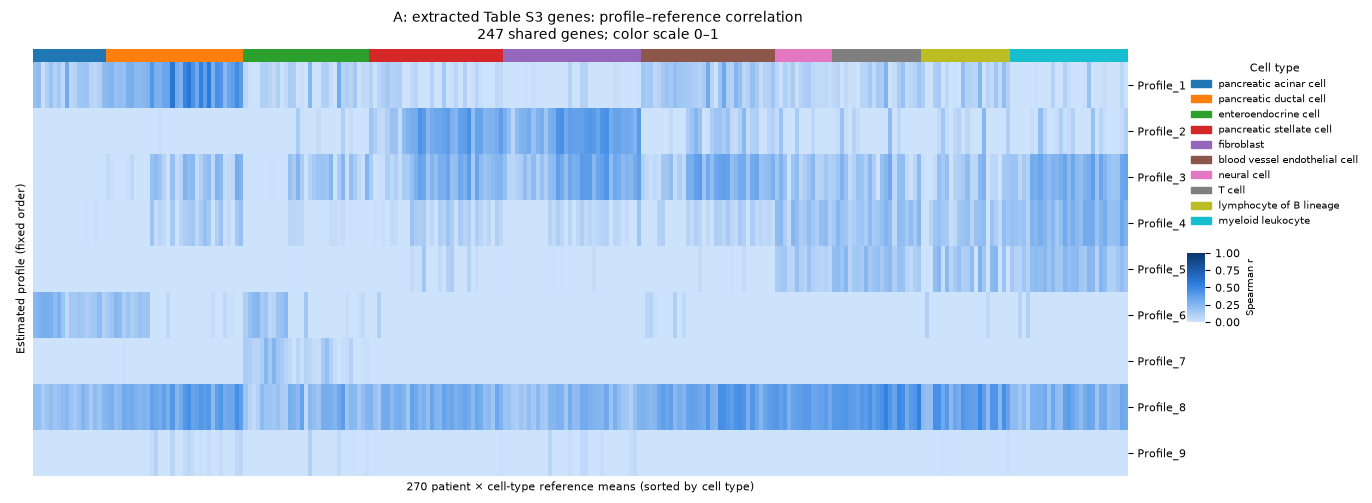

A: extracted Table S3 genes: 247 genes; saved paper_duplication/figures/fig_a_papergenes_profile_reference_correlation.png


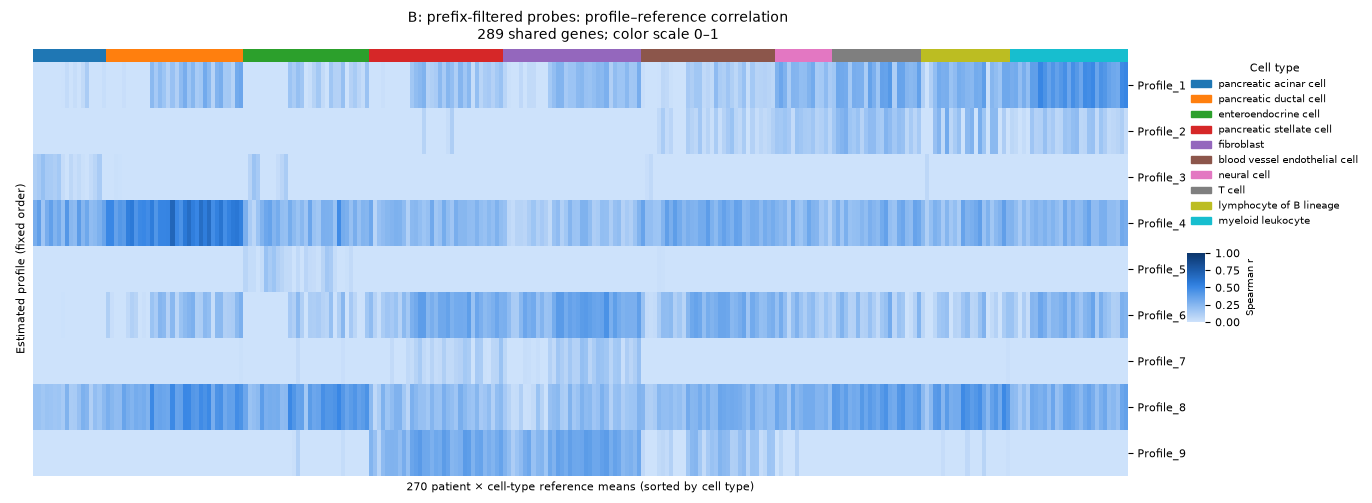

B: prefix-filtered probes: 289 genes; saved paper_duplication/figures/fig_b_nohk_profile_reference_correlation.png


In [22]:
# Reuse Figure 2's patient × cell-type reference means and visual layout.
cell_type_order = [
    "pancreatic acinar cell", "pancreatic ductal cell", "enteroendocrine cell",
    "pancreatic stellate cell", "fibroblast", "blood vessel endothelial cell", "neural cell",
    "T cell", "lymphocyte of B lineage", "myeloid leukocyte",
]
if set(cell_type_order) != set(ref_cell_types.unique()):
    raise ValueError("Cell-type order must cover the reference metadata")
cell_palette = dict(zip(cell_type_order, sns.color_palette("tab10", len(cell_type_order))))
patients = pd.Series(refs.columns, index=refs.columns).str.split("_").str[0]
if patients.eq("").any() or not refs.columns.str.contains("_").all():
    raise ValueError("Expected patient-prefixed reference cell IDs")
group_key = patients + " | " + ref_cell_types.astype(str)
reference_means = refs.T.groupby(group_key, sort=True).mean().T
pb_cell_types = pd.Series({c: c.split(" | ", 1)[1] for c in reference_means.columns})
pb_order = pb_cell_types.map({t: i for i, t in enumerate(cell_type_order)}).sort_values(kind="stable").index
reference_means = reference_means.loc[:, pb_order]
profile_order = [f"Profile_{i}" for i in range(1, 10)]
correlation_panels = {}
shared_probe_counts = {}

for label, cfg in runs.items():
    profiles = pd.read_csv(Path(cfg["stage1_dir"]) / "cell_type_profiles.tsv", sep="\t", index_col=0)
    genes = [gene for gene in read_genes(cfg["probes"])
             if gene in refs.index and gene in profiles.index]
    if len(genes) < 3:
        raise ValueError(f"{label}: insufficient shared genes")
    combined = pd.concat([reference_means.loc[genes], profiles.loc[genes, profile_order]], axis=1)
    correlations = combined.corr(method="spearman").loc[profile_order, pb_order]
    if not np.isfinite(correlations.to_numpy()).all():
        raise ValueError(f"{label}: undefined correlations; check for constant expression vectors")
    correlation_panels[label] = correlations
    shared_probe_counts[label] = len(genes)

# Fixed display scale; retain signed values in matrices and TSV exports.
vmin, vmax = 0.0, 1.0
heatmap_dir = Path("paper_duplication/figures")
heatmap_dir.mkdir(parents=True, exist_ok=True)
titles = {"A_paperGenes": "A: extracted Table S3 genes", "B_noHK": "B: prefix-filtered probes"}

for label, correlations in correlation_panels.items():
    grid = sns.clustermap(
        correlations, row_cluster=False, col_cluster=False,
        col_colors=pb_cell_types.loc[pb_order].map(cell_palette).to_numpy(),
        cmap=seq_blue, vmin=vmin, vmax=vmax,
        xticklabels=False, yticklabels=True, figsize=(12, 4.6),
        cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.02, 0.02),
    )
    grid.ax_heatmap.set_xlabel(f"{len(pb_order)} patient × cell-type reference means (sorted by cell type)")
    grid.ax_heatmap.set_ylabel("Estimated profile (fixed order)")
    grid.ax_heatmap.yaxis.set_label_position("left")
    grid.ax_heatmap.tick_params(axis="y", rotation=0)
    handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
    legend = grid.ax_heatmap.legend(
        handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
        loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
    )
    grid.fig.suptitle(f"{titles[label]}: profile–reference correlation\n"
                      f"{shared_probe_counts[label]} shared genes; color scale 0–1", y=1.04, fontsize=10)
    grid.fig.canvas.draw()
    bbox = legend.get_window_extent(grid.fig.canvas.get_renderer()).transformed(grid.fig.transFigure.inverted())
    grid.cax.set_position([bbox.x0, bbox.y0 - 0.20, 0.015, 0.15])
    grid.cax.yaxis.label.set_fontsize(7)
    output = heatmap_dir / f"fig_{label.lower()}_profile_reference_correlation.png"
    grid.savefig(output, dpi=200, bbox_inches="tight")
    correlations.to_csv(output.with_suffix(".tsv"), sep="\t")
    plt.show()
    plt.close(grid.fig)
    print(f"{titles[label]}: {shared_probe_counts[label]} genes; saved {output}")


### 3. Different reference preprocessing procedures

`03_paper_style_reference_processing.ipynb` compares single-cell and five-cell pseudo-bulk references. The local export has approximately equal cell totals, so original sequencing-depth ranking cannot be recovered; grouping is randomized instead. This is an approximation, not a full reconstruction of the paper's processing.

Run C pretransforms the reference and is unsuitable for judging the intended intervention. Run D passes untransformed pseudo-bulk values to the CLI. In the local code, `normalise_bulk` jointly quantile-normalizes bulk and reference before its per-gene transform; `normalise_refs_independent` separately transforms the reference for correlation labeling. These are distinct paths. Avoid preapplying the transform to either input.

The recorded Run D maximum breadth is 7/10, and its most frequently dominant profile wins in 102/150 samples. This configuration did not lower those descriptive metrics relative to A. It does not rule out reference-processing effects, because grouping, source data, and evaluation references differ.

Across runs, a frequently dominant profile has no reference-type correlation above 0.3. This means low similarity by this metric, not zero correlation. Its identity and malignancy remain unresolved. Assess marker enrichment, alignment across fits, reference coverage, and association with independently measured purity before assigning a tumor label.